# Credit Card Fraud Detection: Initial Report and Exploratory Data Analysis

**Capstone Assignment 20.1**

This notebook covers data understanding, cleaning, outlier analysis, feature engineering and a baseline model for the research question:

> *Can a machine learning model flag fraudulent credit card transactions accurately enough to catch most fraud while keeping false alarms on legitimate customers low?*

**Contents**
1. Setup and data loading
2. Data overview
3. Data cleaning (missing values, duplicates)
4. Exploratory data analysis
5. Outlier analysis
6. Feature engineering
7. Train/test split (time-ordered)
8. Baseline model: Logistic Regression
9. Summary of findings and next steps

## 1. Setup and Data Loading

In [1]:
# Core libraries
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling and evaluation
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    PrecisionRecallDisplay
)

import warnings
warnings.filterwarnings("ignore")

# Consistent plot styling
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42

In [2]:
# Dataset: Kaggle "Credit Card Fraud Detection" (mlg-ulb/creditcardfraud)
# Download creditcard.csv from https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
# and place it in the data/ folder (the file is not committed to GitHub because of its size).
df_raw = pd.read_csv("data/creditcard.csv")
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
df_raw.head()

Rows: 284,807 | Columns: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Data Overview

| Column | Description |
|---|---|
| `Time` | Seconds elapsed since the first transaction (covers ~2 days) |
| `V1`–`V28` | Anonymized features produced by PCA (to protect cardholder confidentiality) |
| `Amount` | Transaction amount (euros) |
| `Class` | Target: 1 = fraud, 0 = legitimate |

All columns are numeric. Because `V1`–`V28` are PCA components, they are already centered and mutually uncorrelated, but they cannot be interpreted in business terms. `Time` and `Amount` are the only raw, interpretable features.

In [3]:
# Data types and memory footprint
df_raw.info(verbose=False)

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Columns: 31 entries, Time to Class
dtypes: float64(30), int64(1)
memory usage: 67.4 MB


In [4]:
# Summary statistics for the interpretable columns
df_raw[["Time", "Amount", "Class"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.86,47488.15,0.0,54201.5,84692.0,139320.50,172792.00
Amount,284807.0,88.35,250.12,0.0,5.6,22.0,77.16,25691.16
Class,284807.0,0.00,0.04,0.0,0.0,0.0,0.00,1.00


In [5]:
# Class balance
class_counts = df_raw["Class"].value_counts()
class_pct = df_raw["Class"].value_counts(normalize=True) * 100
pd.DataFrame({"count": class_counts, "percent": class_pct.round(3)}).rename(index={0: "Legitimate", 1: "Fraud"})

,count,percent
Class,,
Legitimate,284315,99.827
Fraud,492,0.173


**Observation:** only about **0.17%** of transactions are fraudulent, roughly 1 in every 580. This extreme imbalance drives every later decision: accuracy will be misleading, and the evaluation metric must focus on the rare fraud class.

## 3. Data Cleaning

### 3.1 Missing values

In [6]:
# Count missing values per column (show only columns that have any)
missing = df_raw.isna().sum()
print(f"Total missing values: {missing.sum()}")
missing[missing > 0]

Total missing values: 0


Series([], dtype: int64)

No missing values are present, so no imputation is required.

### 3.2 Duplicate rows

In [7]:
# Identify exact duplicate rows
n_dupes = df_raw.duplicated().sum()
dupe_fraud = df_raw[df_raw.duplicated()]["Class"].sum()
print(f"Duplicate rows: {n_dupes:,} ({n_dupes / len(df_raw):.2%} of data)")
print(f"Of which fraud: {dupe_fraud}")

Duplicate rows: 1,081 (0.38% of data)
Of which fraud: 19


In [8]:
# Remove duplicates: identical rows (same time, amount and all 28 features) are almost
# certainly repeated records, and keeping them would let the same transaction appear
# in both training and test sets.
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Rows after removing duplicates: {len(df):,}")
print(f"Fraud cases after removing duplicates: {df['Class'].sum()} ({df['Class'].mean():.3%})")

Rows after removing duplicates: 283,726
Fraud cases after removing duplicates: 473 (0.167%)


## 4. Exploratory Data Analysis

### 4.1 Class distribution

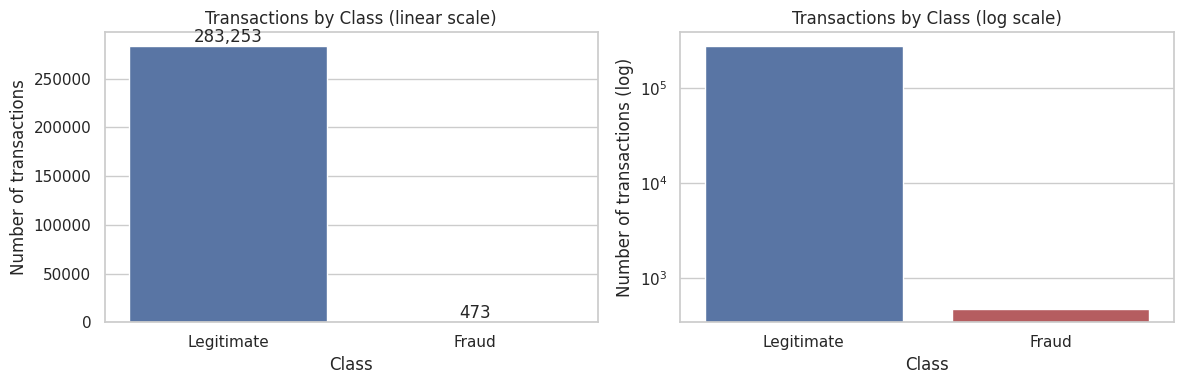

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Linear scale: shows how dominant the legitimate class is
counts = df["Class"].map({0: "Legitimate", 1: "Fraud"}).value_counts()
sns.barplot(x=counts.index, y=counts.values, palette=["#4C72B0", "#C44E52"], ax=axes[0])
axes[0].set_title("Transactions by Class (linear scale)")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of transactions")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

# Log scale: makes the fraud bar visible
sns.barplot(x=counts.index, y=counts.values, palette=["#4C72B0", "#C44E52"], ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Transactions by Class (log scale)")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Number of transactions (log)")

plt.tight_layout()
plt.show()

### 4.2 Transaction amount

In [10]:
# Compare amount statistics for each class
df.groupby("Class")["Amount"].describe().rename(index={0: "Legitimate", 1: "Fraud"}).round(2)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
Legitimate,283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
Fraud,473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87


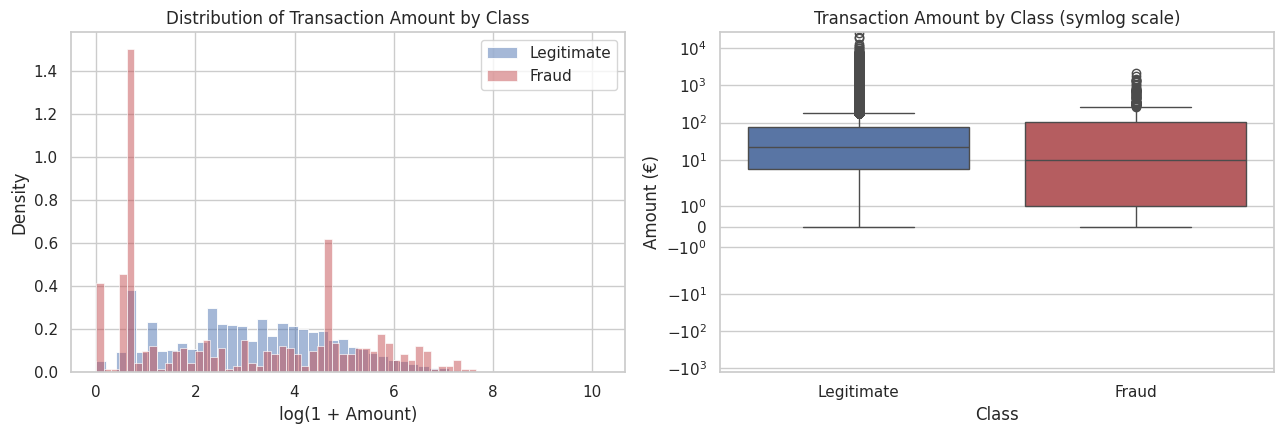

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Distribution of log-amount by class (density, so the small fraud class is comparable)
for cls, color, label in [(0, "#4C72B0", "Legitimate"), (1, "#C44E52", "Fraud")]:
    sns.histplot(np.log1p(df.loc[df["Class"] == cls, "Amount"]), bins=50, stat="density",
                 color=color, alpha=0.5, label=label, ax=axes[0])
axes[0].set_title("Distribution of Transaction Amount by Class")
axes[0].set_xlabel("log(1 + Amount)")
axes[0].set_ylabel("Density")
axes[0].legend()

# Boxplot on log scale to compare spread and outliers
sns.boxplot(data=df, x=df["Class"].map({0: "Legitimate", 1: "Fraud"}), y="Amount",
            palette=["#4C72B0", "#C44E52"], ax=axes[1])
axes[1].set_yscale("symlog")
axes[1].set_title("Transaction Amount by Class (symlog scale)")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Amount (€)")

plt.tight_layout()
plt.show()

In [12]:
# Share of fraud by amount band: are small "test" transactions riskier?
amount_bins = [-0.01, 1, 10, 50, 100, 500, 1000, df["Amount"].max()]
amount_labels = ["≤1", "1–10", "10–50", "50–100", "100–500", "500–1k", ">1k"]
df_band = df.assign(AmountBand=pd.cut(df["Amount"], bins=amount_bins, labels=amount_labels))
band_summary = df_band.groupby("AmountBand", observed=True)["Class"].agg(transactions="count", fraud="sum", fraud_rate="mean")
band_summary["fraud_rate"] = (band_summary["fraud_rate"] * 100).round(3)
band_summary

,transactions,fraud,fraud_rate
AmountBand,,,
≤1,30331,171,0.564
1–10,69490,67,0.096
10–50,90327,55,0.061
50–100,37179,55,0.148
100–500,47290,91,0.192
500–1k,6174,25,0.405
>1k,2935,9,0.307


**Observations:**
- Fraudulent transactions have a higher mean amount (€124 vs €88) but a much lower median (€9.82 vs €22): fraud is concentrated at very small amounts (36% of fraud is €1 or less, consistent with card-testing, where a fraudster checks whether a stolen card works) and a tail of larger amounts.
- Transactions of €1 or less have a fraud rate of 0.56%, more than three times the overall rate.
- Amount alone does not separate the classes well; the distributions overlap heavily.

### 4.3 Time of day

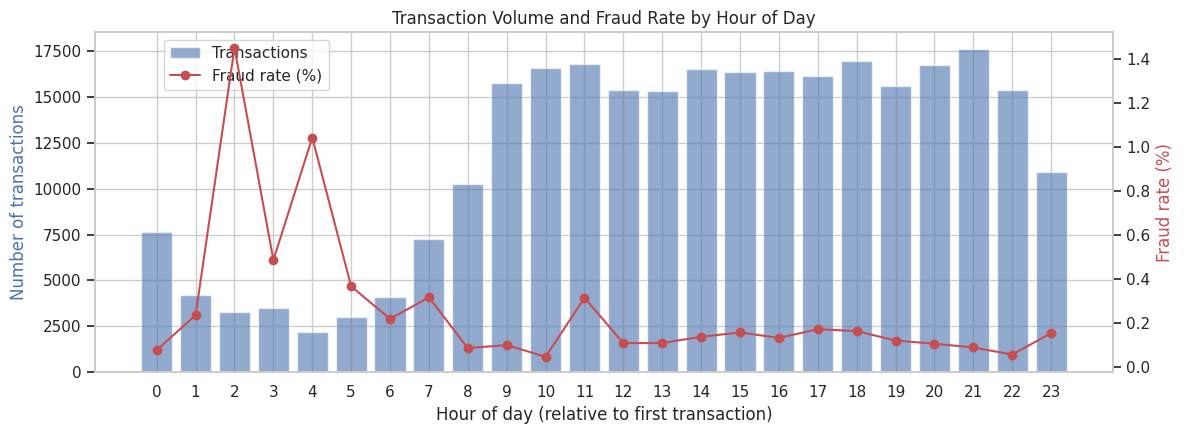

In [13]:
# Time is seconds from the first transaction; convert to hour of day (dataset spans ~2 days)
hour = (df["Time"] // 3600) % 24
hourly = df.assign(Hour=hour).groupby("Hour")["Class"].agg(transactions="count", fraud="sum")
hourly["fraud_rate_pct"] = hourly["fraud"] / hourly["transactions"] * 100

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(hourly.index, hourly["transactions"], color="#4C72B0", alpha=0.6, label="Transactions")
ax1.set_xlabel("Hour of day (relative to first transaction)")
ax1.set_ylabel("Number of transactions", color="#4C72B0")
ax1.set_xticks(range(0, 24))

ax2 = ax1.twinx()
ax2.plot(hourly.index, hourly["fraud_rate_pct"], color="#C44E52", marker="o", label="Fraud rate (%)")
ax2.set_ylabel("Fraud rate (%)", color="#C44E52")
ax2.grid(False)

ax1.set_title("Transaction Volume and Fraud Rate by Hour of Day")
handles = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(handles, ["Transactions", "Fraud rate (%)"], loc="upper left", bbox_to_anchor=(0.06, 1.0))
plt.tight_layout()
plt.show()

**Observation:** legitimate volume follows a clear day/night cycle, dropping sharply in hours 1–7 (likely night time). Fraud does not drop as much, so the **fraud rate spikes during low-volume night hours**, peaking at about 1.45% in hour 2, nearly 9 times the overall rate. This makes hour-of-day a useful engineered feature.

### 4.4 Which anonymized features separate fraud from legitimate transactions?

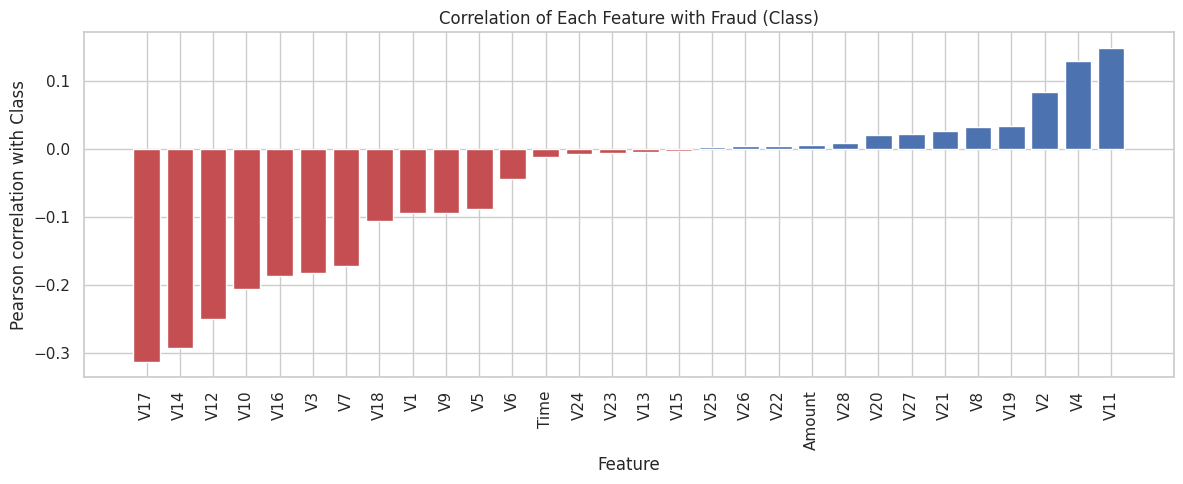

In [14]:
# Correlation of each feature with the target
corr_with_class = df.drop(columns="Class").corrwith(df["Class"]).sort_values()

fig, ax = plt.subplots(figsize=(12, 5))
colors = ["#C44E52" if v < 0 else "#4C72B0" for v in corr_with_class.values]
ax.bar(corr_with_class.index, corr_with_class.values, color=colors)
ax.set_title("Correlation of Each Feature with Fraud (Class)")
ax.set_xlabel("Feature")
ax.set_ylabel("Pearson correlation with Class")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

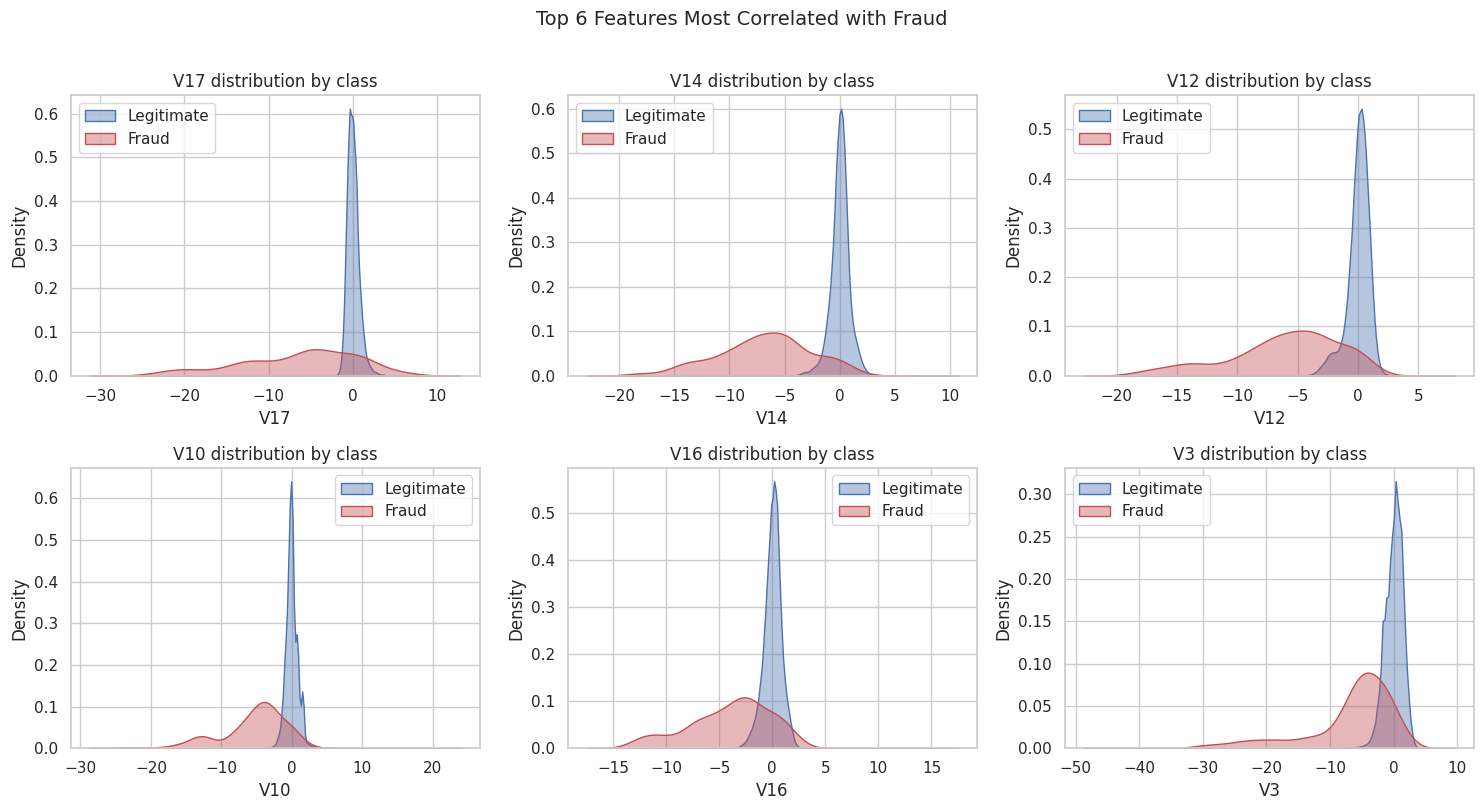

In [15]:
# Distributions of the six features most strongly correlated with fraud
top_features = corr_with_class.abs().sort_values(ascending=False).head(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.flat, top_features):
    for cls, color, label in [(0, "#4C72B0", "Legitimate"), (1, "#C44E52", "Fraud")]:
        sns.kdeplot(df.loc[df["Class"] == cls, feat], fill=True, alpha=0.4,
                    color=color, label=label, ax=ax, common_norm=False)
    ax.set_title(f"{feat} distribution by class")
    ax.set_xlabel(feat)
    ax.set_ylabel("Density")
    ax.legend()
plt.suptitle("Top 6 Features Most Correlated with Fraud", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

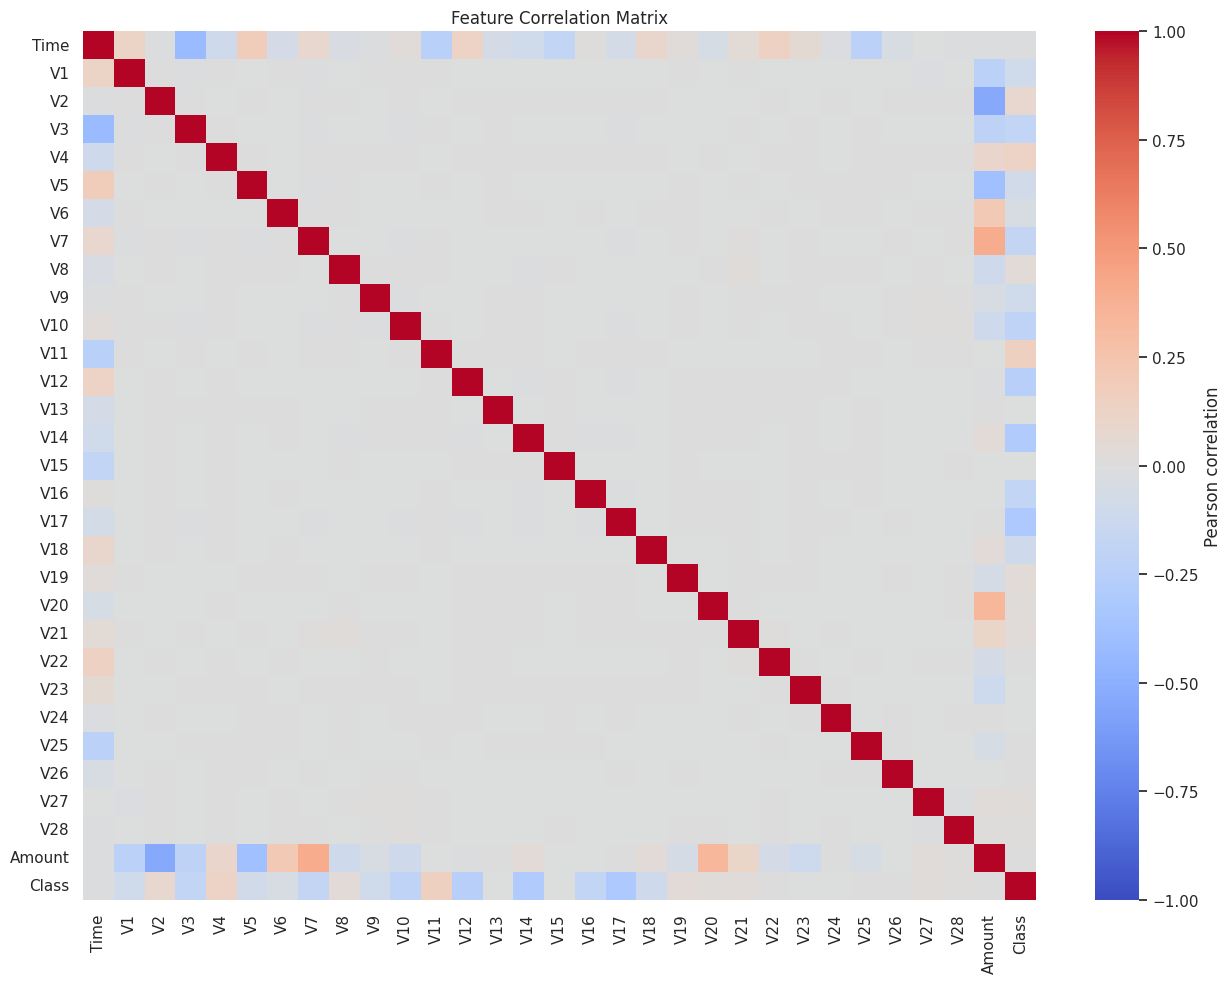

In [16]:
# Correlation heatmap: confirms the PCA features are uncorrelated with each other
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(df.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1,
            cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

**Observations:**
- Features **V17, V14, V12, V10, V16 and V3** show the strongest (negative) relationship with fraud (|r| between 0.18 and 0.31); their fraud distributions are shifted far from those of legitimate transactions.
- As expected from PCA, the V-features are essentially uncorrelated with each other, so multicollinearity is not a concern for Logistic Regression. `Amount` and `Time` do correlate with some V-features.

## 5. Outlier Analysis

In [17]:
# IQR method on Amount
q1, q3 = df["Amount"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
is_amount_outlier = df["Amount"] > upper_fence

print(f"Amount IQR upper fence: €{upper_fence:,.2f}")
print(f"Amount outliers: {is_amount_outlier.sum():,} ({is_amount_outlier.mean():.2%} of transactions)")
print(f"Fraud rate among amount outliers: {df.loc[is_amount_outlier, 'Class'].mean():.3%}")
print(f"Fraud rate among non-outliers:   {df.loc[~is_amount_outlier, 'Class'].mean():.3%}")

Amount IQR upper fence: €185.38
Amount outliers: 31,685 (11.17% of transactions)
Fraud rate among amount outliers: 0.275%
Fraud rate among non-outliers:   0.153%


In [18]:
# Z-score method on the PCA features: how many transactions have at least one extreme value?
v_cols = [f"V{i}" for i in range(1, 29)]
z_scores = (df[v_cols] - df[v_cols].mean()) / df[v_cols].std()
extreme_count = (z_scores.abs() > 4).sum(axis=1)
has_extreme = extreme_count > 0

outlier_summary = pd.DataFrame({
    "transactions": [(~has_extreme).sum(), has_extreme.sum()],
    "fraud": [df.loc[~has_extreme, "Class"].sum(), df.loc[has_extreme, "Class"].sum()],
}, index=["No extreme V-value", "≥1 extreme V-value (|z| > 4)"])
outlier_summary["fraud_rate_pct"] = (outlier_summary["fraud"] / outlier_summary["transactions"] * 100).round(3)
outlier_summary

,transactions,fraud,fraud_rate_pct
No extreme V-value,270113,66,0.024
≥1 extreme V-value (|z| > 4),13613,407,2.990


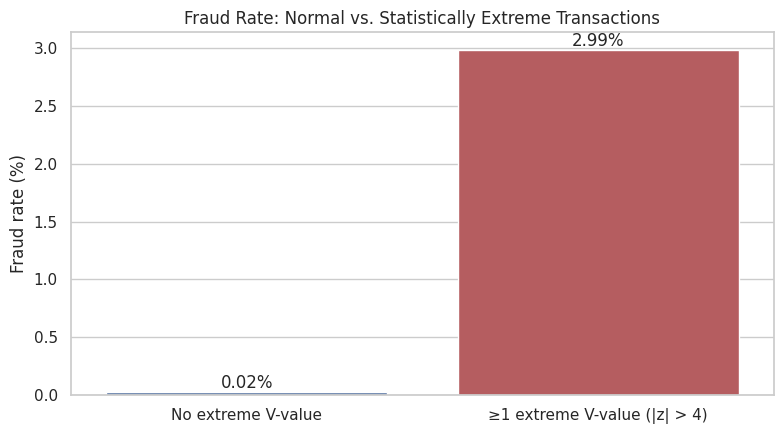

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=outlier_summary.index, y=outlier_summary["fraud_rate_pct"], palette=["#4C72B0", "#C44E52"], ax=ax)
ax.set_title("Fraud Rate: Normal vs. Statistically Extreme Transactions")
ax.set_xlabel("")
ax.set_ylabel("Fraud rate (%)")
for i, v in enumerate(outlier_summary["fraud_rate_pct"]):
    ax.text(i, v, f"{v:.2f}%", ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Decision: outliers are kept.** In most projects outliers are noise to be removed. Here, **fraud *is* the anomaly**: the 4.8% of transactions with at least one extreme V-value contain 86% of all fraud, and their fraud rate (2.99%) is over 100 times that of the remaining transactions (0.024%). Amount outliers (above the €185 IQR fence) also have a higher fraud rate (0.28% vs 0.15%). Removing them would delete exactly the signal the model needs. Instead, scaling (and later, robust tree-based models) will handle their influence. This finding also supports the plan to test unsupervised anomaly detection (Isolation Forest, One-Class SVM) in Module 24.

## 6. Feature Engineering

In [20]:
df_fe = df.copy()

# Hour of day: captures the night-time fraud-rate spike seen in section 4.3
df_fe["Hour"] = (df_fe["Time"] // 3600) % 24

# Night flag: hours 1-7 had low volume and elevated fraud rates
df_fe["IsNight"] = df_fe["Hour"].between(1, 7).astype(int)

# Log-transformed amount: reduces the heavy right skew of Amount
df_fe["LogAmount"] = np.log1p(df_fe["Amount"])

# Micro-transaction flag: very small amounts are associated with card-testing
df_fe["IsMicroAmount"] = (df_fe["Amount"] <= 1).astype(int)

new_features = ["Hour", "IsNight", "LogAmount", "IsMicroAmount"]
df_fe[new_features + ["Class"]].groupby("Class").mean().rename(index={0: "Legitimate", 1: "Fraud"}).round(3)

,Hour,IsNight,LogAmount,IsMicroAmount
Class,,,,
Legitimate,14.050,0.097,3.154,0.106
Fraud,11.655,0.298,2.838,0.362


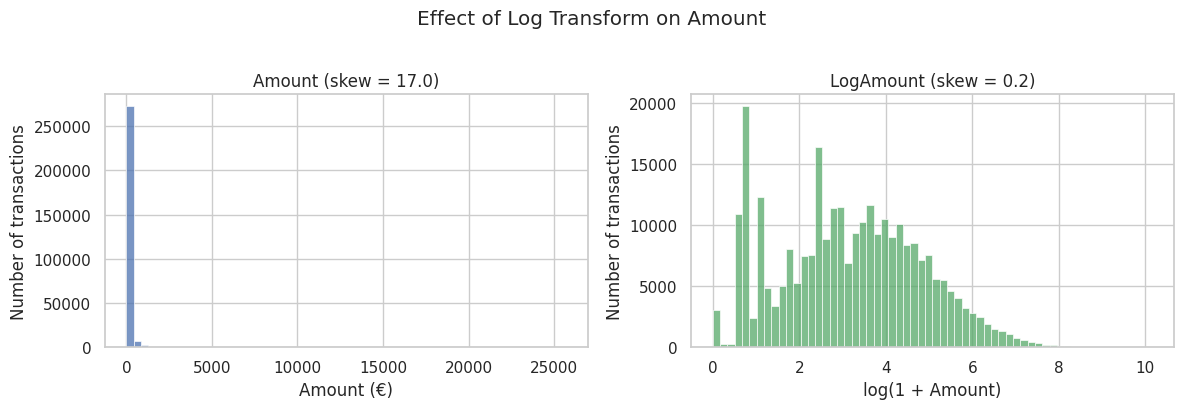

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Skew before and after log transform
sns.histplot(df_fe["Amount"], bins=60, color="#4C72B0", ax=axes[0])
axes[0].set_title(f"Amount (skew = {df_fe['Amount'].skew():.1f})")
axes[0].set_xlabel("Amount (€)")
axes[0].set_ylabel("Number of transactions")

sns.histplot(df_fe["LogAmount"], bins=60, color="#55A868", ax=axes[1])
axes[1].set_title(f"LogAmount (skew = {df_fe['LogAmount'].skew():.1f})")
axes[1].set_xlabel("log(1 + Amount)")
axes[1].set_ylabel("Number of transactions")

plt.suptitle("Effect of Log Transform on Amount", y=1.02)
plt.tight_layout()
plt.show()

**Feature set for modeling:** `V1`–`V28`, `LogAmount`, `Hour`, `IsNight`, `IsMicroAmount`.
Raw `Time` is dropped (it only encodes position in the 2-day window and would not generalize to future data), and raw `Amount` is replaced by `LogAmount`. All features are standardized inside the model pipeline.

## 7. Train/Test Split (Time-Ordered)

A bank trains on past transactions and scores future ones. To mimic this and avoid leakage, transactions are sorted by `Time` and the **first 80% are used for training and the last 20% for testing**, instead of a random split.

In [22]:
feature_cols = v_cols + ["LogAmount", "Hour", "IsNight", "IsMicroAmount"]

df_sorted = df_fe.sort_values("Time").reset_index(drop=True)
split_idx = int(len(df_sorted) * 0.8)
train, test = df_sorted.iloc[:split_idx], df_sorted.iloc[split_idx:]

X_train, y_train = train[feature_cols], train["Class"]
X_test, y_test = test[feature_cols], test["Class"]

split_summary = pd.DataFrame({
    "rows": [len(train), len(test)],
    "fraud": [y_train.sum(), y_test.sum()],
    "fraud_rate_pct": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["Train (first 80%)", "Test (last 20%)"]).round(3)
split_summary

,rows,fraud,fraud_rate_pct
Train (first 80%),226980,399,0.176
Test (last 20%),56746,74,0.130


## 8. Baseline Model: Logistic Regression

### 8.1 Choice of evaluation metric

**Primary metric: Precision-Recall AUC (Average Precision).**

- **Accuracy is unsuitable:** a model that always predicts "legitimate" is ~99.8% accurate but catches zero fraud.
- **ROC-AUC is over-optimistic** when negatives vastly outnumber positives, because the false-positive rate stays tiny even when there are many false alarms in absolute terms.
- **PR-AUC focuses on the fraud class.** It summarizes the trade-off between *recall* (share of fraud caught) and *precision* (share of alerts that are real fraud) across all thresholds. A random model scores roughly the fraud rate (~0.0017), so the metric has a meaningful floor.

**Supporting metrics:** recall and precision at the default 0.5 threshold, which map directly to business outcomes: missed fraud (losses) and false alarms (review cost and customer friction).

### 8.2 Models
- **Dummy classifier** (always predicts the majority class): shows why accuracy fails.
- **Logistic Regression (unweighted):** standard baseline.
- **Logistic Regression (class-weighted):** penalizes missed fraud more heavily to counter the imbalance.

In [23]:
def evaluate(model, name, X_tr, y_tr, X_te, y_te):
    """Fit a model and return its key test-set metrics as a dict."""
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_score = model.predict_proba(X_te)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_te, y_pred),
        "PR-AUC": average_precision_score(y_te, y_score),
        "ROC-AUC": roc_auc_score(y_te, y_score),
        "Precision": precision_score(y_te, y_pred, zero_division=0),
        "Recall": recall_score(y_te, y_pred),
        "F1": f1_score(y_te, y_pred),
    }

models = {
    "Dummy (always legitimate)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "Logistic Regression (class-weighted)": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
}

results = pd.DataFrame([evaluate(m, n, X_train, y_train, X_test, y_test) for n, m in models.items()]).set_index("Model")
results.round(4)

,Accuracy,PR-AUC,ROC-AUC,Precision,Recall,F1
Model,,,,,,
Dummy (always legitimate),0.9987,0.0013,0.5000,0.0000,0.0000,0.0000
Logistic Regression,0.9992,0.7393,0.9811,0.8163,0.5405,0.6504
Logistic Regression (class-weighted),0.9575,0.7694,0.9864,0.0279,0.9324,0.0541


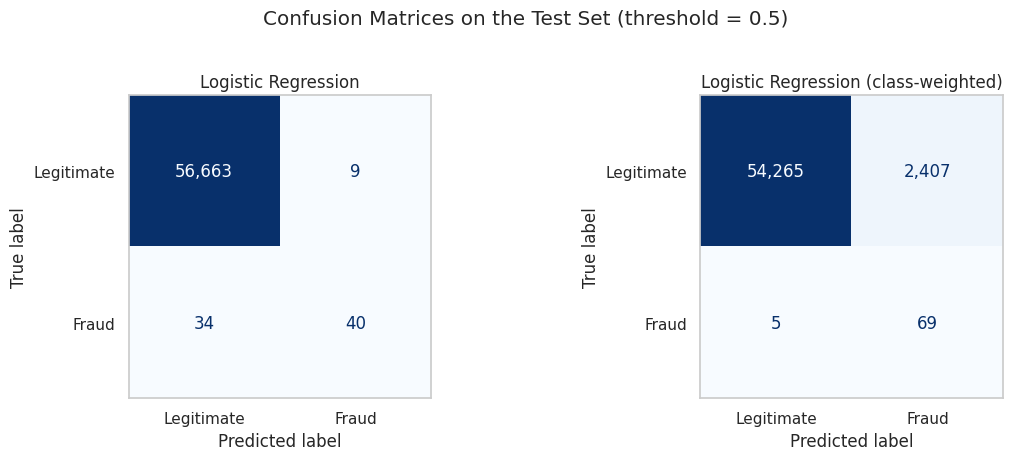

In [24]:
# Confusion matrices for the two Logistic Regression models
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, ["Logistic Regression", "Logistic Regression (class-weighted)"]):
    ConfusionMatrixDisplay.from_estimator(
        models[name], X_test, y_test, display_labels=["Legitimate", "Fraud"],
        cmap="Blues", values_format=",", colorbar=False, ax=ax
    )
    ax.set_title(name)
    ax.grid(False)
plt.suptitle("Confusion Matrices on the Test Set (threshold = 0.5)", y=1.02)
plt.tight_layout()
plt.show()

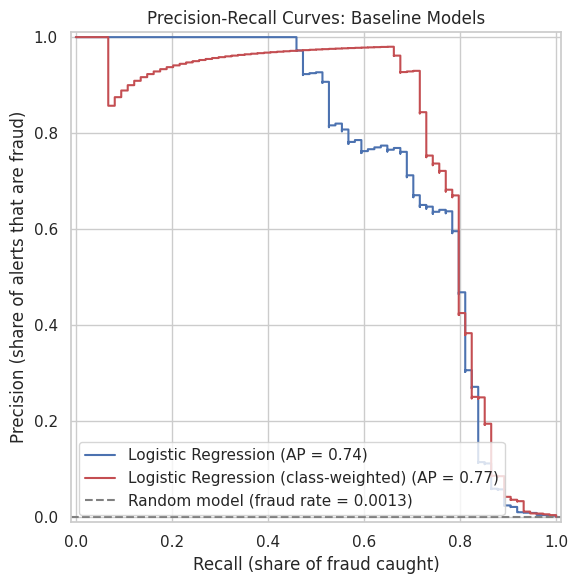

In [25]:
# Precision-Recall curves
fig, ax = plt.subplots(figsize=(8, 6))
for name, color in [("Logistic Regression", "#4C72B0"), ("Logistic Regression (class-weighted)", "#C44E52")]:
    PrecisionRecallDisplay.from_estimator(models[name], X_test, y_test, name=name, color=color, ax=ax)
ax.axhline(y_test.mean(), linestyle="--", color="grey", label=f"Random model (fraud rate = {y_test.mean():.4f})")
ax.set_title("Precision-Recall Curves: Baseline Models")
ax.set_xlabel("Recall (share of fraud caught)")
ax.set_ylabel("Precision (share of alerts that are fraud)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

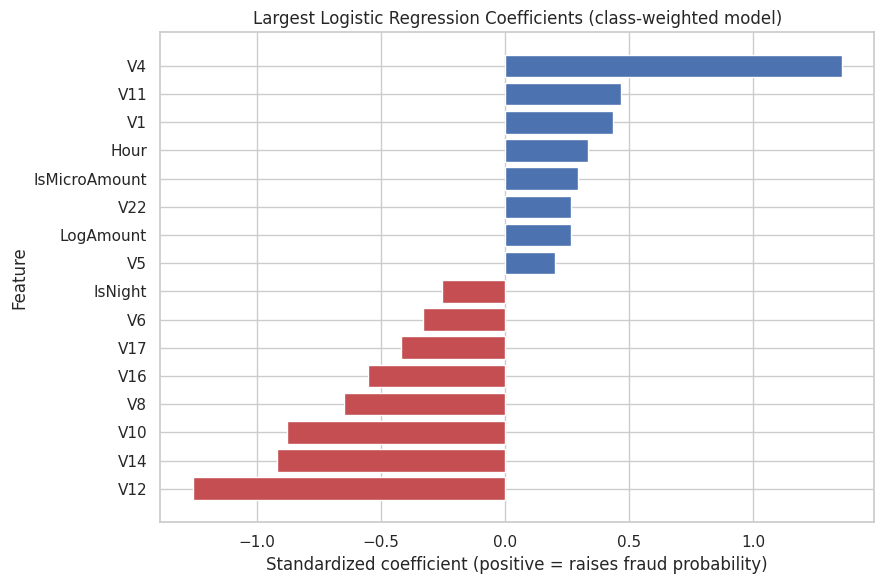

In [26]:
# Which features drive the baseline model? (standardized coefficients)
lr_weighted = models["Logistic Regression (class-weighted)"].named_steps["clf"]
coefs = pd.Series(lr_weighted.coef_[0], index=feature_cols).sort_values()
top_coefs = pd.concat([coefs.head(8), coefs.tail(8)])

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_coefs.index, top_coefs.values, color=["#C44E52" if v < 0 else "#4C72B0" for v in top_coefs.values])
ax.set_title("Largest Logistic Regression Coefficients (class-weighted model)")
ax.set_xlabel("Standardized coefficient (positive = raises fraud probability)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

In [27]:
# Business view of the trade-off: alerts generated vs. fraud caught at different thresholds
y_score_w = models["Logistic Regression (class-weighted)"].predict_proba(X_test)[:, 1]
rows = []
for t in [0.5, 0.8, 0.9, 0.95, 0.99, 0.999]:
    pred = (y_score_w >= t).astype(int)
    tp = ((pred == 1) & (y_test == 1)).sum()
    rows.append({
        "Threshold": t,
        "Alerts raised": int(pred.sum()),
        "Fraud caught": int(tp),
        "Fraud missed": int(y_test.sum() - tp),
        "False alarms": int(pred.sum() - tp),
        "Recall": tp / y_test.sum(),
        "Precision": tp / pred.sum() if pred.sum() else 0,
    })
pd.DataFrame(rows).set_index("Threshold").round(3)

,Alerts raised,Fraud caught,Fraud missed,False alarms,Recall,Precision
Threshold,,,,,,
0.500,2476,69,5,2407,0.932,0.028
0.800,714,64,10,650,0.865,0.090
0.900,307,63,11,244,0.851,0.205
0.950,195,61,13,134,0.824,0.313
0.990,109,59,15,50,0.797,0.541
0.999,79,57,17,22,0.770,0.722


## 9. Summary of Findings and Next Steps

In [28]:
# Key numbers used in the summary below
best = results.loc["Logistic Regression (class-weighted)"]
base = results.loc["Logistic Regression"]
print(f"Clean dataset: {len(df):,} transactions, {df['Class'].sum()} fraud ({df['Class'].mean():.3%})")
print(f"Dummy accuracy: {results.loc['Dummy (always legitimate)', 'Accuracy']:.4f} with recall 0")
print(f"LR unweighted   -> PR-AUC {base['PR-AUC']:.3f}, recall {base['Recall']:.3f}, precision {base['Precision']:.3f}")
print(f"LR class-weight -> PR-AUC {best['PR-AUC']:.3f}, recall {best['Recall']:.3f}, precision {best['Precision']:.3f}")

Clean dataset: 283,726 transactions, 473 fraud (0.167%)
Dummy accuracy: 0.9987 with recall 0
LR unweighted   -> PR-AUC 0.739, recall 0.541, precision 0.816
LR class-weight -> PR-AUC 0.769, recall 0.932, precision 0.028


### Findings
- **Data quality:** no missing values; 1,081 duplicate rows (19 of them fraud) were removed, leaving 283,726 transactions with 473 frauds (0.167%).
- **Imbalance is the core challenge:** the dummy model that never flags fraud scores 99.87% accuracy on the test set while catching nothing, so accuracy is rejected in favor of **PR-AUC**, supported by recall and precision.
- **Patterns in the data:** fraud rates spike during low-volume night hours (up to ~1.45% in hour 2), 36% of fraud is €1 or less (card-testing), and a handful of anonymized features (V17, V14, V12, V10) separate fraud strongly.
- **Outliers are signal, not noise:** the 4.8% of transactions with extreme feature values hold 86% of all fraud, so outliers were retained.
- **Baseline Logistic Regression** (time-ordered test set of 56,746 transactions, 74 frauds):
  - Unweighted: PR-AUC **0.739**; catches 54% of fraud with 82% precision.
  - Class-weighted: PR-AUC **0.769**; catches 93% of fraud, but only 2.8% of its 2,476 alerts are real fraud.
  - Raising the class-weighted model's threshold to 0.99 catches 80% of fraud with 54% precision (109 alerts). **Threshold choice is a business decision**, not a technical default.

### Next steps 
1. Train Random Forest and XGBoost, which can capture non-linear patterns the linear baseline misses.
2. Compare imbalance strategies (class weights, SMOTE inside a pipeline, undersampling) using time-aware cross-validation.
3. Add Isolation Forest and One-Class SVM as unsupervised anomaly detectors for unseen fraud patterns.
4. Choose a decision threshold by minimizing total business cost (missed fraud amount + cost per false alarm).
5. Translate results into a non-technical summary: fraud caught, losses prevented, and alerts per day.